In [30]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
from  tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
from tensorflow.keras.applications import VGG16
import os

In [31]:
from google.colab import files

uploaded = files.upload()

Saving fashion mnist.zip to fashion mnist (1).zip


In [32]:
import zipfile

with zipfile.ZipFile('fashion mnist.zip', 'r') as zip_ref:
    zip_ref.extractall('/content/fashion_data2')

In [33]:
path = "/content/fashion_data2/fashion mnist"

dataset = tf.keras.utils.image_dataset_from_directory(
    path,
    image_size=(128, 128),
    batch_size=32
)

print("labels : ", dataset.class_names)

Found 12832 files belonging to 11 classes.
labels :  ['Ankle-boot', 'Bag', 'Coat', 'Dress', 'Pullover', 'Sandal', 'Shirt', 'Sneaker', 'T-shirt-top', 'Trouser', 'train']


In [34]:
train_size = int(0.8 * len(dataset))
train_ds = dataset.take(train_size)
test_ds = dataset.skip(train_size)
print("Split complete")

Split complete


In [40]:
base_model = tf.keras.applications.MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(128, 128, 3)
)
print("VGG16 loaded")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
VGG16 loaded


In [41]:
for layer in base_model.layers:
  layer.trainable = False

print("Model layer frozen")

Model layer frozen


In [45]:
model = Sequential([
    tf.keras.layers.Resizing(128, 128),
    base_model,
    GlobalAveragePooling2D(),
    Dense(128, activation='relu'),
    Dense(11, activation='softmax')
])
print("custom layers added")

custom layers added


In [46]:
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
print("model compiled")

model compiled


In [47]:
history = model.fit(train_ds, validation_data=test_ds, epochs = 3)

Epoch 1/3
320/320 ━━━━━━━━━━━━━━━━━━━━ 190s 573ms/step - accuracy: 0.7880 - loss: 0.6141 - val_accuracy: 0.7870 - val_loss: 0.5747
Epoch 2/3
320/320 ━━━━━━━━━━━━━━━━━━━━ 178s 557ms/step - accuracy: 0.8409 - loss: 0.4388 - val_accuracy: 0.8306 - val_loss: 0.4477
Epoch 3/3
320/320 ━━━━━━━━━━━━━━━━━━━━ 181s 567ms/step - accuracy: 0.8559 - loss: 0.3848 - val_accuracy: 0.8526 - val_loss: 0.4085


In [48]:
loss, accuracy = model.evaluate(test_ds)
print("Loss : ", loss)
print("Accuracy : ", accuracy)


81/81 ━━━━━━━━━━━━━━━━━━━━ 42s 483ms/step - accuracy: 0.8526 - loss: 0.4114
Loss :  0.41141119599342346
Accuracy :  0.852623462677002


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 434ms/step


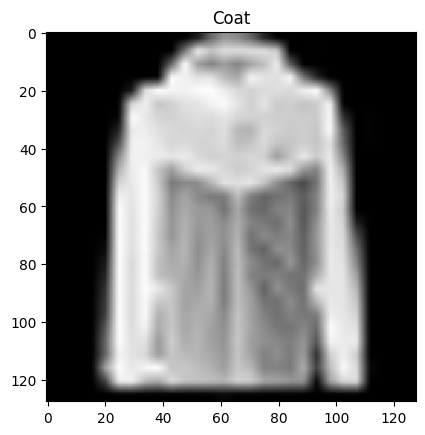

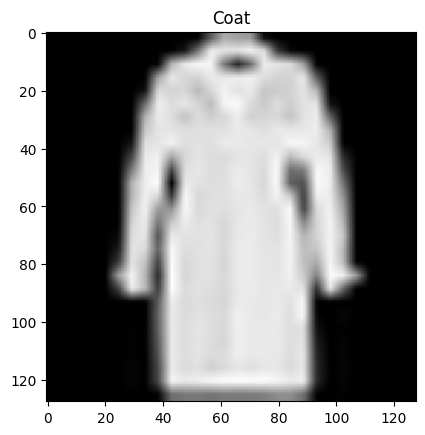

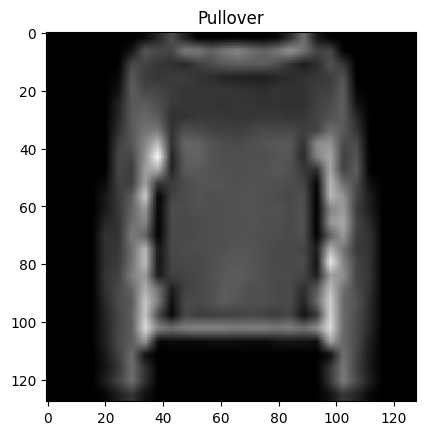

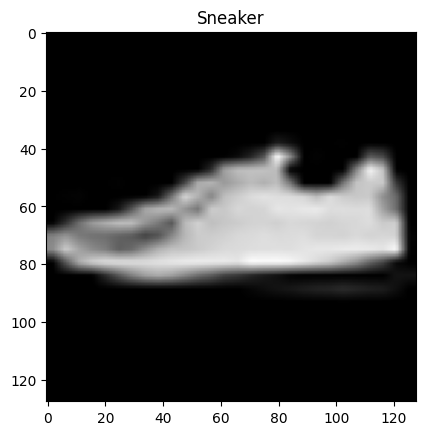

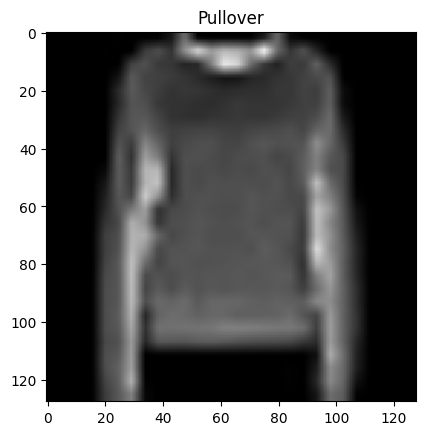

In [50]:
images, labels =  next(iter(test_ds))
predictions = model.predict(images)

for i in range(5):
  plt.imshow(images[i].numpy().astype("uint8"))
  plt.title(dataset.class_names[np.argmax(predictions[i])])
  plt.show()

In [51]:
base_model.trainable = True

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
history = model.fit(train_ds, validation_data =test_ds, epochs =2)

Epoch 1/2
320/320 ━━━━━━━━━━━━━━━━━━━━ 193s 586ms/step - accuracy: 0.8669 - loss: 0.3607 - val_accuracy: 0.8337 - val_loss: 0.4510
Epoch 2/2
320/320 ━━━━━━━━━━━━━━━━━━━━ 181s 567ms/step - accuracy: 0.8782 - loss: 0.3249 - val_accuracy: 0.8345 - val_loss: 0.4622


In [52]:
test_loss, test_accuracy = model.evaluate(test_ds)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

81/81 ━━━━━━━━━━━━━━━━━━━━ 39s 450ms/step - accuracy: 0.8345 - loss: 0.4622
Test Loss: 0.4622228741645813
Test Accuracy: 83.4490716457367 %
